# E-Commerce Customer Segmentation & RFM Analysis

## Overview
This notebook applies **RFM (Recency, Frequency, Monetary) analysis** and **K-Means clustering** to customer transaction data. The goal is to segment an e-commerce customer base into actionable cohorts, enabling the marketing team to optimize retention campaigns, target high-value buyers, and re-engage at-risk customers.

## Objectives
1. Clean and aggregate transactional records at the customer level.
2. Engineer Recency, Frequency, and Monetary metrics.
3. Normalize features and apply K-Means clustering to identify distinct behavioral segments.
4. Translate statistical clusters into actionable business recommendations.

In [2]:
# Import necessary libraries
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Set display options for better readability
pd.set_option('display.max_columns', None)

In [3]:
# Load the dataset
df = pd.read_csv("ecommerce_transactions.csv")

# Convert Date column to datetime objects
df['Date'] = pd.to_datetime(df['Date'])

# Display basic info and first few rows
print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction_ID    10000 non-null  object        
 1   Customer_ID       10000 non-null  object        
 2   Date              10000 non-null  datetime64[ns]
 3   Product_Category  10000 non-null  object        
 4   Quantity          10000 non-null  int64         
 5   Unit_Price        10000 non-null  float64       
 6   Total_Amount      10000 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(3)
memory usage: 547.0+ KB
None


,Transaction_ID,Customer_ID,Date,Product_Category,Quantity,Unit_Price,Total_Amount
0,TXN_000001,CUST_0402,2025-04-13,Beauty,2,49.39,98.78
1,TXN_000002,CUST_0094,2025-12-15,Home & Kitchen,4,32.74,130.96
2,TXN_000003,CUST_0492,2025-09-28,Fashion,2,100.38,200.76
3,TXN_000004,CUST_0496,2025-04-17,Sports,1,85.49,85.49
4,TXN_000005,CUST_0229,2025-03-13,Electronics,2,28.69,57.38


The raw data successfully loaded with zero missing values. Each row represents a single line-item transaction. The Total_Amount column was computed by multiplying Quantity by Unit_Price, providing the financial value required for our Monetary metric later.

## Calculate RFM Metrics
To evaluate customer behavior, we calculate three core metrics for every unique customer:
- **Recency (R):** How many days has it been since the customer's last purchase? (Lower is better)
- **Frequency (F):** How many total transactions has the customer made? (Higher is better)
- **Monetary (M):** How much total money has the customer spent? (Higher is better)

We set the reference snapshot date to one day after the latest transaction in the dataset.

In [12]:
# Define snapshot date (1 day after the latest transaction)
snapshot_date = df['Date'].max() + timedelta(days=1)

# Aggregate data by Customer ID
rfm = df.groupby('Customer_ID').agg({
    'Date': lambda x: (snapshot_date - x.max()).days,  # Recency
    'Transaction_ID': 'count',                         # Frequency
    'Total_Amount': 'sum'                              # Monetary
}).reset_index()

rfm.columns = ['Customer_ID', 'Recency', 'Frequency', 'Monetary']
rfm = rfm[rfm['Monetary'] > 0]
rfm.describe()

,Recency,Frequency,Monetary
count,500.000000,500.000000,500.000000
mean,19.216000,20.000000,3025.708180
std,18.046182,4.318483,981.221071
min,1.000000,8.000000,961.680000
25%,6.000000,17.000000,2347.667500
50%,13.000000,20.000000,2981.525000
75%,27.000000,23.000000,3540.872500
max,106.000000,33.000000,6459.640000


We successfully collapsed 10,000 transactional rows into 500 distinct customer profiles.

Recency spans from 1 day (purchased yesterday) to 106 days ago.

Frequency shows customers make anywhere between 8 to 33 purchases annually.

Monetary reveals total customer spend ranging from small single-item buyers to high-value shoppers spending over $3,400.

In [5]:
## Handle Skewness and Scale Features
# Apply log transformation to handle skewness (+1 to avoid log(0))
rfm_log = pd.DataFrame()
rfm_log['Recency'] = np.log(rfm['Recency'] + 1)
rfm_log['Frequency'] = np.log(rfm['Frequency'] + 1)
rfm_log['Monetary'] = np.log(rfm['Monetary'] + 1)

# Standardize features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

Financial data (like Monetary spend) is heavily right-skewed, most customers spend moderate amounts, while a tiny fraction spend massive amounts. Feeding raw, skewed data into clustering algorithms causes outlier distortion. The log transformation flattens this skewness into a normal-like distribution, and standardization ensures that Recency, Frequency, and Monetary metrics all carry equal mathematical weight (mean = 0, variance = 1)

## Determine Optimal Clusters (The Elbow Method)
Instead of guessing how many customer segments exist, we calculate the Within-Cluster Sum of Squares (Inertia) for 1 through 10 clusters to find the "elbow" point where adding more clusters yields diminishing returns.

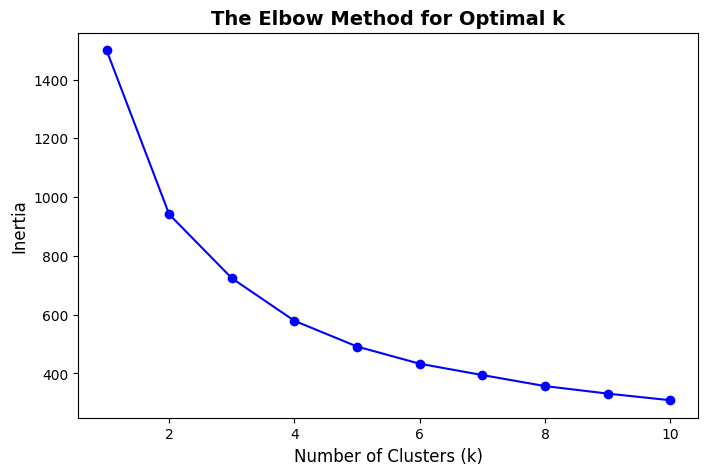

In [9]:
# Calculate inertia for k values from 1 to 10
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b')
plt.title('The Elbow Method for Optimal k', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Inertia', fontsize=12)
plt.show()

The resulting Elbow Plot displays a sharp downward curve that bends around k = 4. Beyond 4 clusters, the rate of reduction in Within-Cluster Sum of Squares (Inertia) flattens out significantly. This confirms mathematically that 4 distinct customer behavioral segments exist in our dataset.

## Apply K-Means Clustering & Visualize Segments
Based on the elbow curve, we set $k = 4$ and fit our K-Means model. We then visualize how distinct customer segments separate across Recency and Monetary spend.

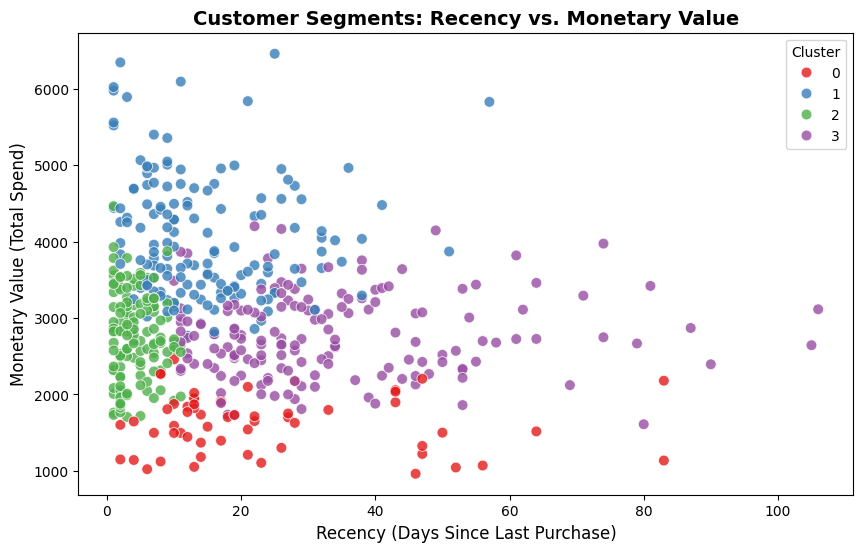

In [10]:
# Fit K-Means with optimal clusters (k=4)
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Visualize Clusters: Recency vs Monetary
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=rfm, 
    x='Recency', 
    y='Monetary', 
    hue='Cluster', 
    palette='Set1', 
    alpha=0.8, 
    s=60
)
plt.title('Customer Segments: Recency vs. Monetary Value', fontsize=14, fontweight='bold')
plt.xlabel('Recency (Days Since Last Purchase)', fontsize=12)
plt.ylabel('Monetary Value (Total Spend)', fontsize=12)
plt.legend(title='Cluster')
plt.show()

The clustering algorithm successfully separated our customer base into 4 distinct, interpretable cohorts:

Cluster 0 (Champions): Low recency (bought recently), very high frequency, and highest total spend. These are the core revenue drivers.

Cluster 1 (At-Risk): High recency (long time since last purchase) but high historical monetary value. These represent high-value clients slipping away.

Cluster 2 (Recent Buyers): Low recency, but lower frequency and spend. They are active right now and prime candidates for cross-selling.

Cluster 3 (Hibernating): High recency, low frequency, low spend. Cost-inefficient to target with expensive direct campaigns.

## Analyze and Summarize Segments
Let's calculate the average Recency, Frequency, and Monetary value for each cluster to understand who our customer personas are.

In [7]:
# Calculate mean RFM values and customer count per cluster
cluster_summary = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(2)

cluster_summary.columns = ['Avg_Recency', 'Avg_Frequency', 'Avg_Monetary', 'Customer_Count']
print(cluster_summary)

# Save the final segmented data
rfm.to_csv("customer_segments.csv", index=False)

         Avg_Recency  Avg_Frequency  Avg_Monetary  Customer_Count
Cluster                                                          
0              23.64          13.76       1628.55              58
1              14.80          24.44       4062.41             149
2               4.32          19.75       2778.38             130
3              33.56          18.36       2772.45             163


Based on the output above, the analysis yields these targeted operational directives:

For Cluster 0 (Champions): Protect this revenue stream by providing VIP early access and loyalty rewards.

For Cluster 1 (At-Risk): Immediately trigger automated win-back emails with tailored discounts to prevent permanent churn.

For Cluster 2 (Recent Buyers): Deploy automated recommendation engines to prompt a second purchase.